# Theta_reg analysis — rare vs typical events

Same setup as `turb_theta_reg_all.ipynb` (only `Theta_reg`, mean +- std across seeds), but every real-data analysis is split by a rare/typical classification of the whole `x1` dataset (not the hand-picked `selected_samples.pt` events).

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path
import sys, os, re, math
from types import SimpleNamespace

root = Path().resolve()
sys.path.insert(0, str(root / '../codes'))
from sde_routines import *
from utils import *
from utils_experiment import *
from filters_bank import *
from potentials import *
from ortho_wavelet import *
from check_potentials import *  # theta_column_map, decode_mod2_stq, etc.

sys.path.insert(0, str(root / '../data'))
from data_loader import *

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device, '|', root)

pd.set_option('display.float_format', lambda x: f'{x:.3g}')

%matplotlib inline

device: cuda | /lustre/fswork/projects/rech/wbg/ukv59en/MGD-for-Maximum-Entropy-Generation/turbulence


In [2]:
import os

# LOCAL vs JEAN ZAY -- load_turbulence_1d()'s default path in data_loader.py
# is Jean-Zay-only (/lustre/...). Flip to "jean_zay" there instead of editing this.
# PHI_CHUNK_SIZE batches phi(x)/grad(x) evaluation over the sample dim -- evaluating
# Scattering_Fourth_Order_Mod2_{Real,Imag}_Q1 on the full n1=5000 batch at once
# materializes a ~5.9GB intermediate BEFORE any reduction (measured directly:
# DefaultCPUAllocator asked for exactly 5898240000 bytes) -- chunking avoids it
# with no change to the result. Jean Zay has enough RAM/GPU memory to skip it.
RUN_LOCATION = "local"   # "local" or "jean_zay"

if RUN_LOCATION == "local" and torch.cuda.is_available():
    # A fixed chunk_size=500 assumes a GPU mostly to ourselves. On a GPU shared with
    # other processes (measured here: a co-tenant job holding ~19.5/22GB, leaving as
    # little as ~40MB free) that assumption breaks and 500 alone can still OOM. The
    # ~5.9GB/5000-sample intermediate above scales to ~1.2MiB/sample, so size the
    # chunk from what's ACTUALLY free right now (measured before potentials/data are
    # loaded, so this slightly overestimates later headroom -- the 2x margin covers
    # that plus the other job's usage not being static).
    free_bytes, _ = torch.cuda.mem_get_info()
    BYTES_PER_SAMPLE = 1.2 * 1024 ** 2
    PHI_CHUNK_SIZE = max(1, int(free_bytes / BYTES_PER_SAMPLE / 2))
    print(f"GPU free memory: {free_bytes / 1e6:.0f}MB -> PHI_CHUNK_SIZE = {PHI_CHUNK_SIZE}")
else:
    PHI_CHUNK_SIZE = 500 if RUN_LOCATION == "local" else None

if RUN_LOCATION == "local":
    local_turbulence_path = (root / "../data/data_files/turbulence_1d_period.pt").resolve()
    if local_turbulence_path.exists():
        os.environ["TURBULENCE_1D_DATA_PATH"] = str(local_turbulence_path)
    else:
        print(f"WARNING: {local_turbulence_path} not found -- load_turbulence_1d() "
              f"will fall back to its Jean Zay default path and fail locally.")
print(f"RUN_LOCATION = {RUN_LOCATION!r}, PHI_CHUNK_SIZE = {PHI_CHUNK_SIZE!r}")

GPU free memory: 66743MB -> PHI_CHUNK_SIZE = 26521
RUN_LOCATION = 'local', PHI_CHUNK_SIZE = 26521


In [3]:
J, Q, M = 8, 3, 256
sigma = 3.5
nt = 40000
n1 = 5000
lam = 5e-07
regularization = 1e-2

W = DefineWavelet('Db', m=3, device=device)
Data = load_turbulence_1d().to(device)
n1_initial = 1024
Data = split_periodize_reshape(Data, n1_initial)
scales = 2   # M == 256
for j in range(scales):
    Data = W.decompose(Data)[1]

x1 = normalize(Data[:n1])
print('Data shape:', Data.shape, '| x1 shape:', x1.shape)

Data shape: torch.Size([10000, 1, 256]) | x1 shape: torch.Size([5000, 1, 256])


In [4]:
terms = [
    "L_6",
    "L_6_psi",
    "L_2_lowpass",
    "Scattering_Fourth_Order_Mod2_Real_Q1",
    "Scattering_Fourth_Order_Mod2_Imag_Q1",
    "Scalar_psi_gaussianK",
    "Scalar_morlet_gaussianK",
]

base_args = SimpleNamespace(J=J, Q=Q, terms=terms, nt=nt, sigma=sigma,
                              interpolant='Cos', regularization=regularization,
                              lam=lam, n1=n1)

REAL_KEY = "Scattering_Fourth_Order_Mod2_Real_Q1"
IMAG_KEY = "Scattering_Fourth_Order_Mod2_Imag_Q1"
COMPLEX_NAME = "Scattering_Fourth_Order_Mod2_Q1"

potential_colors = {
    "L_6": "tab:blue",
    "L_6_psi": "tab:olive",
    "L_2_lowpass": "tab:green",
    "Scattering_Fourth_Order_Mod2_Real_Q1": "tab:red",
    "Scattering_Fourth_Order_Mod2_Imag_Q1": "tab:purple",
    "Scalar_psi_gaussianK": "tab:orange",
    "Scalar_morlet_gaussianK": "tab:cyan",
}

In [5]:
import gc

def load_potentials_for_config(resolved_config, M, J, Q, terms, root, device):
    filters, filters_Phi = return_Filters(M, J, 1, device=device, include_phi=True)
    filters_Q = return_Filters(M, J, Q, device=device)
    potentials = get_1d_potentials(terms, J, filters, Q, scalar_param=None, parallel=False,
                                     filters_Q=filters_Q, filters_Phi=filters_Phi)
    potentials_dir = Path(root) / "experiments" / resolved_config / "fitted_potentials"
    if not potentials_dir.exists():
        raise FileNotFoundError(f"No fitted_potentials dir for {resolved_config} at {potentials_dir}")
    for name, p in potentials.items():
        p.to(device)
        if not hasattr(p, "is_fitted"):
            continue
        state_path = potentials_dir / f"{name}.pt"
        if not state_path.exists():
            raise FileNotFoundError(f"[{name}] missing fitted state at {state_path}")
        own_filters = p.filters
        loaded = type(p).load_fixed_parameters(state_path, own_filters, map_location=device)
        loaded.to(device)
        potentials[name] = loaded
    return potentials

def _chunked_call(one_chunk_fn, x, chunk_size):
    """Run one_chunk_fn over x in chunks of chunk_size, halving a chunk and
    retrying if it OOMs, instead of trusting chunk_size as exact (it's only ever a
    starting guess -- see PHI_CHUNK_SIZE's cell for why).

    The retry must happen AFTER leaving the except block, not from inside it: while
    Python is still inside an `except` clause, the caught exception's traceback stays
    alive, and a live traceback pins every local variable in the frame that raised it
    -- including whatever CUDA tensor torch.fft had already allocated right before the
    allocator gave up. Recursing from inside the except (as an earlier version of this
    function did) meant those tensors were never released, so retries made memory
    usage climb instead of shrink -- measured directly: our own process's GPU memory
    grew monotonically (622MiB -> 2.7GiB) across repeated halving instead of the
    freed chunk's memory coming back, and the recursion still failed even at a single
    sample. Exiting the except block first lets gc.collect() actually reclaim them."""
    def _try(x_sub):
        try:
            return one_chunk_fn(x_sub)
        except torch.cuda.OutOfMemoryError:
            if x_sub.shape[0] <= 1:
                raise
        # Outside the except block now -- the failed attempt's traceback (and
        # whatever it was pinning) is no longer referenced from here.
        gc.collect()
        torch.cuda.empty_cache()
        mid = x_sub.shape[0] // 2
        return torch.cat([_try(x_sub[:mid]), _try(x_sub[mid:])], dim=0)

    if chunk_size is None or x.shape[0] <= chunk_size:
        return _try(x)
    chunks = []
    for i in range(0, x.shape[0], chunk_size):
        chunks.append(_try(x[i:i + chunk_size]))
        if torch.cuda.is_available():
            gc.collect()
            torch.cuda.empty_cache()
    return torch.cat(chunks, dim=0)

def compute_phi_X(potentials, x, chunk_size=PHI_CHUNK_SIZE):
    # Each chunk's result moves to CPU before the next chunk starts (see
    # compute_phi_grad_X's docstring for why -- same reasoning, phi(x) is just much
    # smaller than grad(x) so it mattered less here, but keeping both consistent).
    def _one_chunk(x_chunk):
        feats = []
        for p in potentials.values():
            feat = p(x_chunk)
            if feat.ndim == 1:
                feat = feat.unsqueeze(1)
            feats.append(feat)
        return torch.cat(feats, dim=-1).detach().cpu()
    return _chunked_call(_one_chunk, x, chunk_size)

def compute_phi_grad_X(potentials, x, chunk_size=PHI_CHUNK_SIZE):
    """Concatenate each potential's own analytic grad(x) along the coefficient axis
    -> (n, d, T): the exact object the MGD force field is built from (compare
    sde_routines.py's grad_potential = torch.cat((grad_potential, potential.grad(x)),
    dim=1)), NOT a generic autograd Jacobian -- several potentials here wrap forward()
    in torch.no_grad(), so autograd through forward() wouldn't work anyway.

    Each chunk is moved to CPU (and the CUDA cache emptied) right after it's computed,
    before the next chunk starts, and _chunked_call halves+retries any chunk that
    still OOMs -- see its docstring for why a single precomputed chunk_size can't be
    trusted on a shared GPU, and why the retry must happen outside the except block.
    Output values are unchanged; only the device changes."""
    def _one_chunk(x_chunk):
        grad_potential = None
        for p in potentials.values():
            g = p.grad(x_chunk)
            grad_potential = g if grad_potential is None else torch.cat((grad_potential, g), dim=1)
        return grad_potential.detach().cpu()
    return _chunked_call(_one_chunk, x, chunk_size)

## Load Theta_reg across seeds

`theta_t`/MGD is never loaded -- only `Theta_reg` (final time step) and each seed's fitted potentials. A seed is dropped if: it fails to load at all, `Theta_reg` is `None` (regularised fit never saved), its `fitted_potentials` are incomplete, or (guard, not expected to trigger) its feature width differs from every other seed's.

In [6]:
pattern = re.compile(
    r"^turbulencesynth_M256_J8_Q3_sigma3.5_nt40000_n1_5000_lam5e-07_seed_(\d+)_terms2f1130a8_20260728_1232$"
)
all_folders = os.listdir(os.path.join(root, "saved_results/samples"))
seed_range = range(300, 350)

theta_reg_final_by_seed = {}   # seed_key -> (n_features,) tensor, Theta_reg[-1]
potentials_by_seed = {}
config_by_seed = {}
expected_n_features = None

for folder in sorted(all_folders):
    match = pattern.match(folder)
    if not match:
        continue
    seed_val = int(match.group(1))
    if seed_val not in seed_range:
        continue
    key = f"seed{seed_val}"
    resolved_config = folder

    loaded_data = try_load_experiment(root, resolved_config, device)
    if not (loaded_data and loaded_data.get('loaded', False)):
        print(f"  -> {key}: failed to load, skipping.")
        continue
    if loaded_data.get('Theta_reg') is None:
        print(f"  -> {key}: no Theta_reg (regularised fit never saved), skipping.")
        continue

    try:
        potentials_k = load_potentials_for_config(
            resolved_config, M, J=base_args.J, Q=base_args.Q,
            terms=base_args.terms, root=root, device=device,
        )
    except FileNotFoundError as e:
        print(f"  -> {key}: incomplete fitted_potentials, skipping: {e}")
        continue

    theta_final = loaded_data['Theta_reg'][-1].detach().cpu()
    n_features_k = theta_final.shape[-1]

    # Guard: verified empirically (all loadable seeds of this sigma/config) that
    # every seed's fitted potentials produce the SAME feature width/active regions --
    # not assumed. A mismatch here would be a genuine anomaly; drop it loudly rather
    # than silently pool mismatched columns into reg_all.
    if expected_n_features is None:
        expected_n_features = n_features_k
        print(f"  -> Reference feature width set from {key}: {expected_n_features}")
    elif n_features_k != expected_n_features:
        print(f"  -> WARNING: {key} has {n_features_k} features, expected "
              f"{expected_n_features} -- fitted potentials differ from every other "
              f"seed so far, dropping this seed.")
        del loaded_data, potentials_k
        continue

    theta_reg_final_by_seed[key] = theta_final
    potentials_by_seed[key] = potentials_k
    config_by_seed[key] = resolved_config
    del loaded_data

print(f"\nLoaded {len(theta_reg_final_by_seed)} usable seeds (Theta_reg only).")

  -> Reference feature width set from seed300: 272

Loaded 50 usable seeds (Theta_reg only).


In [7]:
seed_keys = sorted(theta_reg_final_by_seed.keys(), key=lambda s: int(s.replace("seed", "")))
reg_all = torch.stack([theta_reg_final_by_seed[k] for k in seed_keys])   # (n_seeds, n_features)
n_seeds, n_features = reg_all.shape

theta_reg_mean = reg_all.mean(0).numpy()
theta_reg_std = reg_all.std(0, correction=1).numpy()
print(f"reg_all: {tuple(reg_all.shape)}  ({n_seeds} seeds, {n_features} features)")

# Any one seed's fitted potentials for phi(x) shape/column-decoding -- functionally
# identical across every loaded seed here (verified: same active_flat for both
# Scalar_* potentials across all loaded seeds), so which one doesn't matter.
REFERENCE_SEED = seed_keys[0]
potentials_ref = potentials_by_seed[REFERENCE_SEED]
print(f"Using {REFERENCE_SEED}'s fitted potentials for phi(x) (shape/decoding only, "
      f"never as a theta source -- theta values are always reg_all.mean(0)/std(0)).")

col_map = theta_column_map(potentials_ref, n_features)
family_ranges = {name: (a, a + d) for name, (a, d) in col_map.items()}
for name, (a, b) in family_ranges.items():
    print(f"  {name:45s} [{a:4d}:{b:<4d}]  dim={b - a}")

reg_all: (50, 272)  (50 seeds, 272 features)
Using seed300's fitted potentials for phi(x) (shape/decoding only, never as a theta source -- theta values are always reg_all.mean(0)/std(0)).
  L_6                                           [   0:9   ]  dim=9
  L_6_psi                                       [   9:34  ]  dim=25
  L_2_lowpass                                   [  34:35  ]  dim=1
  Scalar_psi_gaussianK                          [  35:105 ]  dim=70
  Scalar_morlet_gaussianK                       [ 105:132 ]  dim=27
  Scattering_Fourth_Order_Mod2_Real_Q1          [ 132:216 ]  dim=84
  Scattering_Fourth_Order_Mod2_Imag_Q1          [ 216:272 ]  dim=56


## Whole-dataset rare/typical split

Method from `extract_samples.ipynb`: a signal is **rare** if its extremeness, $\max_t |x(t+1)-x(t)|$ (max absolute lag-1 increment), exceeds a percentile of that quantity over the dataset. It is applied to `x1`: the wavelet-decomposed **and normalized** signals that `phi_X` is computed on. So the labels line up with `phi_X`, and the cutoff is in the same units as the model samples (section 6).

`normalize` (`codes/utils.py`) is **global**: one scalar mean and one scalar std for the whole tensor, not per sample. A positive rescaling preserves the ranking, so the split should match one on un-normalized `Data[:n1]`; only the cutoff value changes, by the factor `Data[:n1].std()`. The cell checks both.

In [8]:
def compute_acceleration(Data):
    """a(t) = Data(t+1) - Data(t), lag-1 velocity increment."""
    return Data[..., 1:] - Data[..., :-1]

def extract_rare_typical(Data, criterion='percentile', std_threshold=40,
                          sustained_sigma=10, min_exceedances=3, percentile=95):
    accel = compute_acceleration(Data)
    accel_std = accel.flatten().std(unbiased=True).item()
    B = accel.shape[0]
    reduce_dims = tuple(range(1, accel.ndim))
    per_traj_max_abs_accel = accel.abs().amax(dim=reduce_dims)

    if criterion == 'max_sigma':
        is_rare = per_traj_max_abs_accel > std_threshold * accel_std
        info = dict(accel_std=accel_std, threshold=std_threshold * accel_std)
    elif criterion == 'sustained_sigma':
        exceed_mask = accel.abs() > sustained_sigma * accel_std
        per_traj_exceed_count = exceed_mask.reshape(B, -1).sum(dim=1)
        is_rare = per_traj_exceed_count >= min_exceedances
        info = dict(accel_std=accel_std, threshold=sustained_sigma * accel_std,
                    min_exceedances=min_exceedances, exceed_counts=per_traj_exceed_count)
    elif criterion == 'percentile':
        cutoff = np.percentile(per_traj_max_abs_accel.cpu().numpy(), percentile)
        is_rare = per_traj_max_abs_accel > cutoff
        info = dict(accel_std=accel_std, percentile=percentile, cutoff=cutoff)
    else:
        raise ValueError(f"unknown criterion '{criterion}'")

    idx_rare = torch.nonzero(is_rare).flatten().tolist()
    idx_typical = torch.nonzero(~is_rare).flatten().tolist()
    return idx_typical, idx_rare, info

idx_typical, idx_rare, info_split = extract_rare_typical(x1, criterion='percentile', percentile=95)
category_indices = {'typical': idx_typical, 'rare': idx_rare}
category_colors = {'typical': 'tab:blue', 'rare': 'tab:red'}
cutoff_p95 = info_split['cutoff']   # x1 (normalized) units
print(f"Whole dataset (n1={n1}) split on x1: typical {len(idx_typical)}, rare {len(idx_rare)} | "
      f"cutoff (p{info_split['percentile']}) = {cutoff_p95:.4g} in x1 units")

# Previous split, on un-normalized Data[:n1] -- only to report what changed.
_, idx_rare_old, info_old = extract_rare_typical(Data[:n1], criterion='percentile', percentile=95)
print(f"Old split on Data[:n1]: rare {len(idx_rare_old)}, cutoff (p{info_old['percentile']}) = "
      f"{info_old['cutoff']:.4g} in Data units | overlap with new rare set: "
      f"{len(set(idx_rare) & set(idx_rare_old))}/{len(idx_rare)} | cutoff ratio old/new = "
      f"{info_old['cutoff'] / cutoff_p95:.4g} vs Data[:n1].std() = {Data[:n1].std().item():.4g}")

Whole dataset (n1=5000) split on x1: typical 4750, rare 250 | cutoff (p95) = 0.8473 in x1 units
Old split on Data[:n1]: rare 250, cutoff (p95) = 3.533 in Data units | overlap with new rare set: 250/250 | cutoff ratio old/new = 4.17 vs Data[:n1].std() = 4.17


## Per-family energy, split by category

Same `phi_X`/`family_energy`/`total_log_p_unnorm` as the pooled notebook, just indexed by `category_indices` afterward -- the underlying $\theta^\top\varphi(x)$ computation is identical, only the grouping changes.

**Sign convention** (checked in `sde_routines.py`: the sampler ascends $+\nabla_x\,\theta^\top\varphi$): $p_\theta(x)\propto\exp(+\theta^\top\varphi(x))$, so $\theta^\top\varphi(x)=\log p_\theta(x)+\log Z(\theta)$.
Every "log p contribution" below is $\theta_F^\top\varphi_F(x)$ in this convention: higher means more likely.

In [9]:
phi_X = compute_phi_X(potentials_ref, x1).detach().cpu().numpy()   # (n1, n_features)

# family_energy is theta.phi(x) per family, i.e. a per-family piece of log p_theta(x).
family_energy = {
    name: ((-1)*theta_reg_mean[a:b] * phi_X[:, a:b]).sum(axis=-1)
    for name, (a, b) in family_ranges.items()
}
total_log_p_unnorm = np.sum(np.stack(list(family_energy.values())), axis=0)

comparison = []
ranges_with_total = {**family_ranges, 'TOTAL': (0, n_features)}
for category, idx in category_indices.items():
    for name, (a, b) in ranges_with_total.items():
        sample_totals = phi_X[idx, a:b] @ theta_reg_mean[a:b]
        comparison.append({
            'category': category, 'family': name,
            'mean_total': sample_totals.mean(), 'std_total': sample_totals.std(ddof=1),
        })
comparison_df = pd.DataFrame(comparison)
display(comparison_df.pivot(index='family', columns='category', values=['mean_total', 'std_total']))

mean_total          std_total        
category                                   rare  typical      rare typical
family                                                                    
L_2_lowpass                                14.7     14.2      21.2    20.1
L_6                                       -23.6   -0.183      81.4    7.77
L_6_psi                                   -2.97     2.73      49.4    8.62
Scalar_morlet_gaussianK                    -763     -448       205     182
Scalar_psi_gaussianK                        700 1.36e+03       504     493
Scattering_Fourth_Order_Mod2_Imag_Q1       1.63    0.155        13    1.79
Scattering_Fourth_Order_Mod2_Real_Q1      -2.68    -10.5       230    22.2
TOTAL                                     -75.7      919       718     674

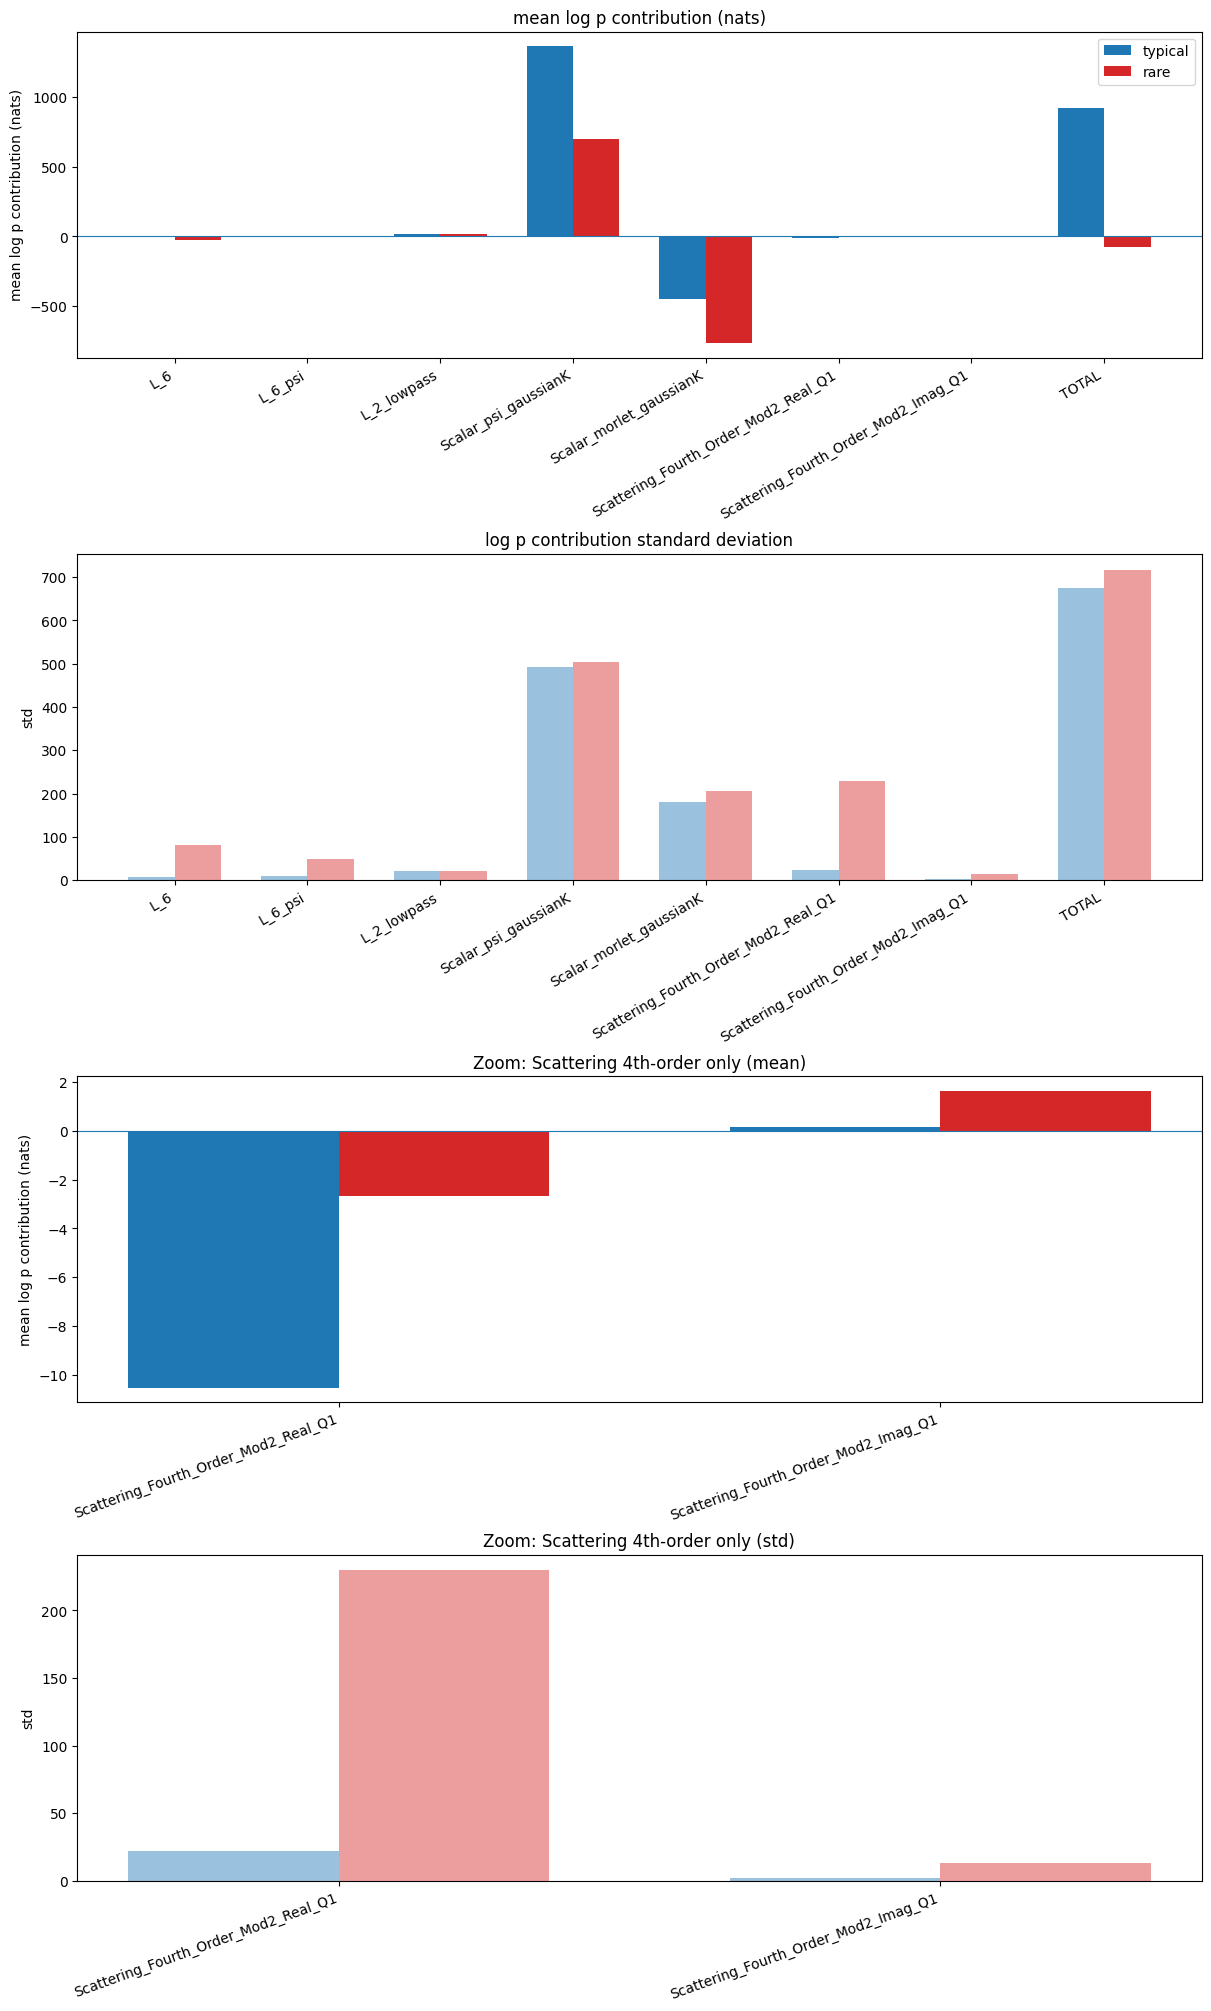

In [10]:
from matplotlib.colors import to_rgba

categories = list(category_indices.keys())
family_names = list(ranges_with_total.keys())   # all families + TOTAL
stats = comparison_df.set_index(['category', 'family'])
means = {c: stats.loc[c].loc[family_names, 'mean_total'].to_numpy() for c in categories}
stds = {c: stats.loc[c].loc[family_names, 'std_total'].to_numpy() for c in categories}
x = np.arange(len(family_names))
width = 0.35

# Scattering-4 (REAL_KEY/IMAG_KEY) bars, zoomed -- their scale is dwarfed by L_6 etc.
# in the full-range panels, so pull just these two out for a readable y-range.
scatter4_families = [REAL_KEY, IMAG_KEY]
zoom_idx = [family_names.index(name) for name in scatter4_families]
x_zoom = np.arange(len(scatter4_families))

fig, (ax_mean, ax_std, ax_mean_zoom, ax_std_zoom) = plt.subplots(4, 1, figsize=(12, 20), constrained_layout=True)
for i, category in enumerate(categories):
    offset = -width / 2 if i == 0 else width / 2
    color = category_colors[category]
    ax_mean.bar(x + offset, means[category], width, label=category, color=color)
    ax_std.bar(x + offset, stds[category], width, label=category, color=to_rgba(color, alpha=0.45))
    ax_mean_zoom.bar(x_zoom + offset, means[category][zoom_idx], width, label=category, color=color)
    ax_std_zoom.bar(x_zoom + offset, stds[category][zoom_idx], width, label=category,
                    color=to_rgba(color, alpha=0.45))

for ax in (ax_mean, ax_mean_zoom):
    ax.axhline(0, linewidth=0.8)
    ax.set_ylabel("mean log p contribution (nats)")
for ax in (ax_std, ax_std_zoom):
    ax.set_ylabel("std")
for ax in (ax_mean, ax_std):
    ax.set_xticks(x)
    ax.set_xticklabels(family_names, rotation=30, ha="right")
for ax in (ax_mean_zoom, ax_std_zoom):
    ax.set_xticks(x_zoom)
    ax.set_xticklabels(scatter4_families, rotation=20, ha="right")
ax_mean.set_title("mean log p contribution (nats)")
ax_std.set_title("log p contribution standard deviation")
ax_mean_zoom.set_title("Zoom: Scattering 4th-order only (mean)")
ax_std_zoom.set_title("Zoom: Scattering 4th-order only (std)")
ax_mean.legend()
plt.show()

## log p, typical vs rare

$\theta^\top\varphi(x)$ = $\log p_\theta(x)$ up to the additive constant $-\log Z(\theta)$ -- the SAME constant for both categories (same $\theta$), so shape and the gap between them are exact; only the absolute axis position is unknown.

typical: gumbel_r: loc=-1238, scale=575, loglik=-3.757e+04, KS D=0.0267 | gumbel_l: loc=-566.2, scale=765.5, loglik=-3.848e+04, KS D=0.115  -> best: gumbel_r
rare: gumbel_r: loc=-269, scale=616.9, loglik=-1996, KS D=0.0587 | gumbel_l: loc=444.7, scale=742.9, loglik=-2027, KS D=0.109  -> best: gumbel_r


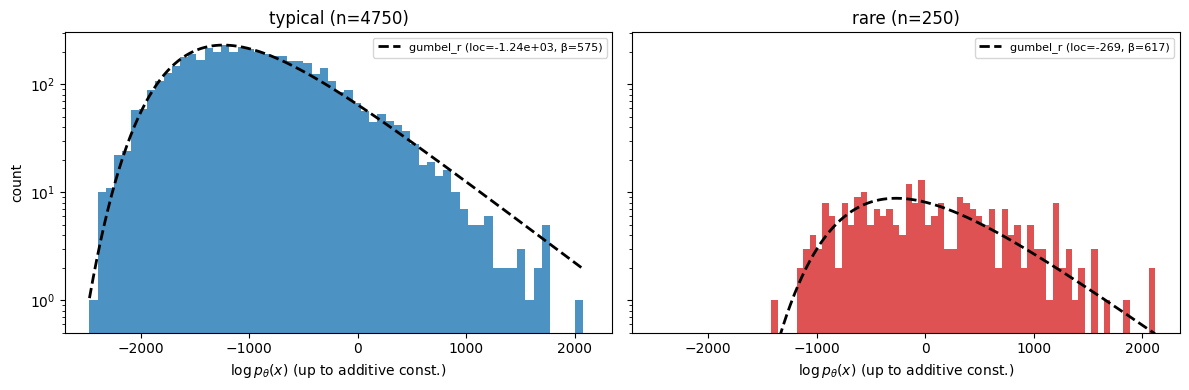

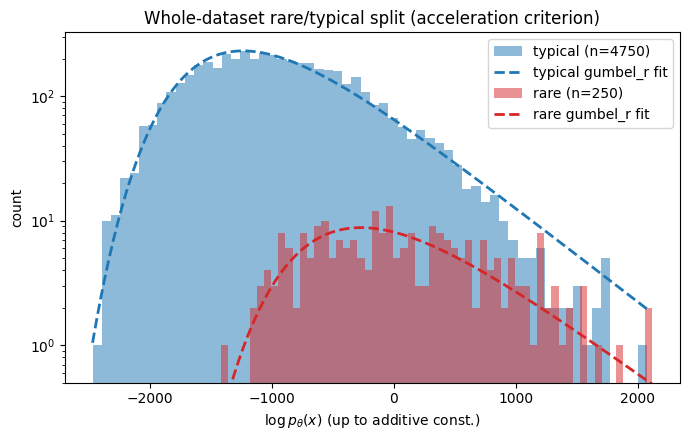

mean log p_theta, up to the same additive constant: typical = -919.1, rare = 75.67  ->  rare < typical: False


In [11]:
from scipy import stats

def _to_np(x):
    return x.detach().cpu().numpy().astype(float) if hasattr(x, 'detach') else np.asarray(x, dtype=float)

logp_by_category = {category: _to_np(total_log_p_unnorm[idx]) for category, idx in category_indices.items()}

# --- Gumbel fit per category: try both orientations, keep the better one by log-likelihood ---
gumbel_fits = {}
for category, x in logp_by_category.items():
    candidates = {}
    for name, dist in (('gumbel_r', stats.gumbel_r), ('gumbel_l', stats.gumbel_l)):
        loc, scale = dist.fit(x)
        candidates[name] = dict(dist=dist, loc=loc, scale=scale,
                                loglik=dist.logpdf(x, loc, scale).sum(),
                                ks=stats.kstest(x, dist.cdf, args=(loc, scale)).statistic)
    best = max(candidates, key=lambda k: candidates[k]['loglik'])
    gumbel_fits[category] = {**candidates[best], 'kind': best}
    print(f"{category}: " + " | ".join(
        f"{k}: loc={c['loc']:.4g}, scale={c['scale']:.4g}, loglik={c['loglik']:.4g}, KS D={c['ks']:.3g}"
        for k, c in candidates.items()) + f"  -> best: {best}")

def _overlay_gumbel(ax, x, edges, fit, color, label=None):
    grid = np.linspace(edges[0], edges[-1], 400)
    bin_width = edges[1] - edges[0]
    ax.plot(grid, fit['dist'].pdf(grid, fit['loc'], fit['scale']) * len(x) * bin_width,
            color=color, lw=2, ls='--', label=label)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)
for ax, (category, logp) in zip(axes, logp_by_category.items()):
    color = category_colors.get(category, 'tab:gray')
    _, edges, _ = ax.hist(logp, bins=60, color=color, alpha=0.8)
    fit = gumbel_fits[category]
    _overlay_gumbel(ax, logp, edges, fit, 'k',
                    label=f"{fit['kind']} (loc={fit['loc']:.3g}, β={fit['scale']:.3g})")
    ax.set_title(f'{category} (n={len(logp)})')
    ax.set_xlabel(r'$\log p_\theta(x)$ (up to additive const.)')
    ax.set_yscale('log')
    ax.set_ylim(bottom=0.5)   # keep the pdf's far tail from stretching the log axis
    ax.legend(fontsize=8)
axes[0].set_ylabel('count')
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 4.5))
for category, logp in logp_by_category.items():
    color = category_colors.get(category, 'tab:gray')
    _, edges, _ = ax.hist(logp, bins=60, color=color, alpha=0.5, label=f'{category} (n={len(logp)})')
    _overlay_gumbel(ax, logp, edges, gumbel_fits[category], color,
                    label=f"{category} {gumbel_fits[category]['kind']} fit")
ax.set_xlabel(r'$\log p_\theta(x)$ (up to additive const.)')
ax.set_ylabel('count')
ax.set_yscale('log')
ax.set_ylim(bottom=0.5)
ax.legend()
ax.set_title('Whole-dataset rare/typical split (acceleration criterion)')
fig.tight_layout()
plt.show()

mean_logp = {category: logp.mean() for category, logp in logp_by_category.items()}
print("mean log p_theta, up to the same additive constant: "
      + ", ".join(f"{category} = {m:.4g}" for category, m in mean_logp.items())
      + f"  ->  rare < typical: {mean_logp['rare'] < mean_logp['typical']}")

As the check above shows, rare events sit at **lower** $\log p_\theta$ (lower model density) than typical ones. The gap between the two means is exact, because $\log Z(\theta)$ is the same for both.

## Florentin's plot 

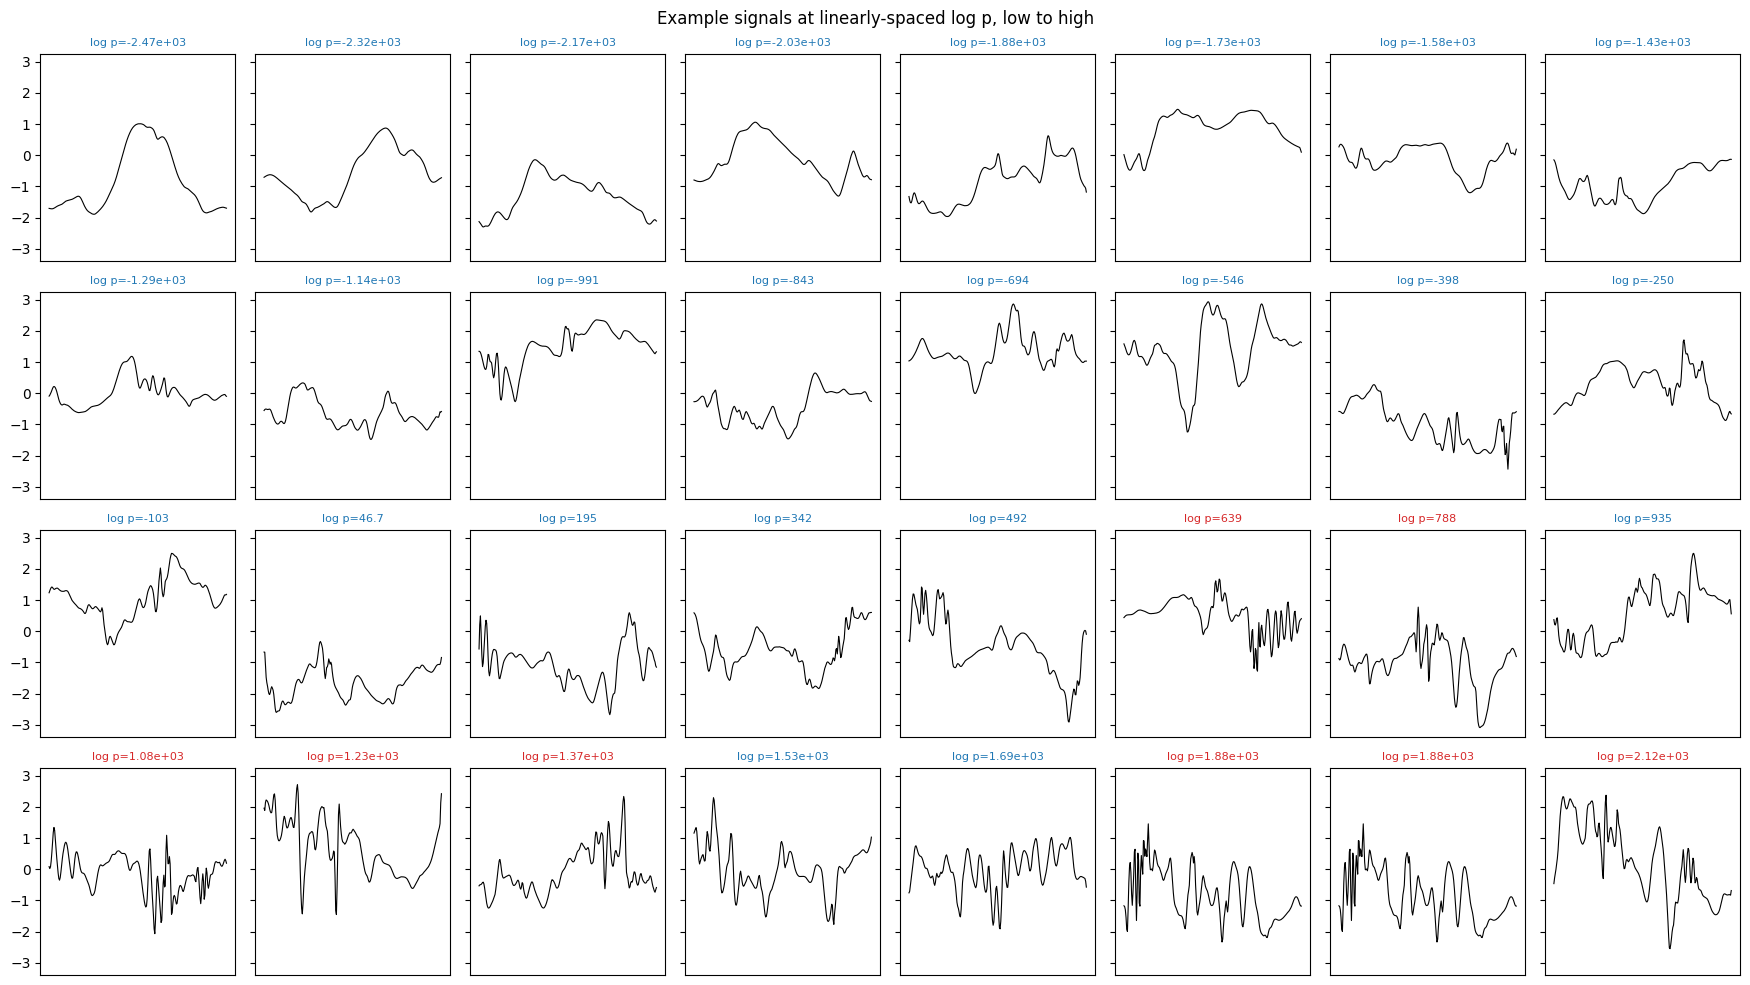

In [12]:
n_examples = 32  # any number; wraps at 8 per row
n_cols = 8
n_rows = math.ceil(n_examples / n_cols)

logp_targets = np.linspace(total_log_p_unnorm.min(), total_log_p_unnorm.max(), n_examples)
example_idx = [int(np.argmin(np.abs(total_log_p_unnorm - t))) for t in logp_targets]

fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.2 * n_cols, 2.5 * n_rows), sharey=True, squeeze=False)
for i, idx in enumerate(example_idx):
    ax = axes[i // n_cols][i % n_cols]
    ax.plot(x1[idx, 0].cpu().numpy(), lw=0.8, color='black')
    label_color = category_colors['rare'] if idx in set(idx_rare) else category_colors['typical']
    ax.set_title(f'log p={total_log_p_unnorm[idx]:.3g}', fontsize=8, color=label_color)
    ax.set_xticks([])
for j in range(n_examples, n_rows * n_cols):
    axes[j // n_cols][j % n_cols].axis('off')
fig.suptitle('Example signals at linearly-spaced log p, low to high')
fig.tight_layout()
plt.show()

## 1. Per-seed family contributions with error bars

For each seed $s$, `C[F][s, i]` $=\theta_{s,F}^\top\varphi_F(x_i)$ (log p contribution, nats), and `D[s, F]` = mean of `C[F][s]` over rare minus mean over typical. The table gives the mean/std of `D` across seeds, plus a bootstrap SE over the `len(idx_rare)` rare signals (resampled with the seed-averaged `C`; typical held fixed). The counts are printed below.

sum(family D) - TOTAL D = -6.104e-05  (should be ~0)
D over 50 seeds; bootstrap: 1000 resamples of the 250 rare signals (typical, n=4750, held fixed)


,family,mean_D,std_D_across_seeds,bootstrap_SE_rare
0,L_6,-23.4,4,5.14
1,L_6_psi,-5.69,3.25,3.03
2,L_2_lowpass,0.507,0.0289,1.28
3,Scalar_psi_gaussianK,-660,4.85,31.2
4,Scalar_morlet_gaussianK,-315,4.56,12.4
5,Scattering_Fourth_Order_Mod2_Real_Q1,7.86,7.41,14.8
6,Scattering_Fourth_Order_Mod2_Imag_Q1,1.48,1.45,0.821
7,TOTAL,-995,4.23,44.4


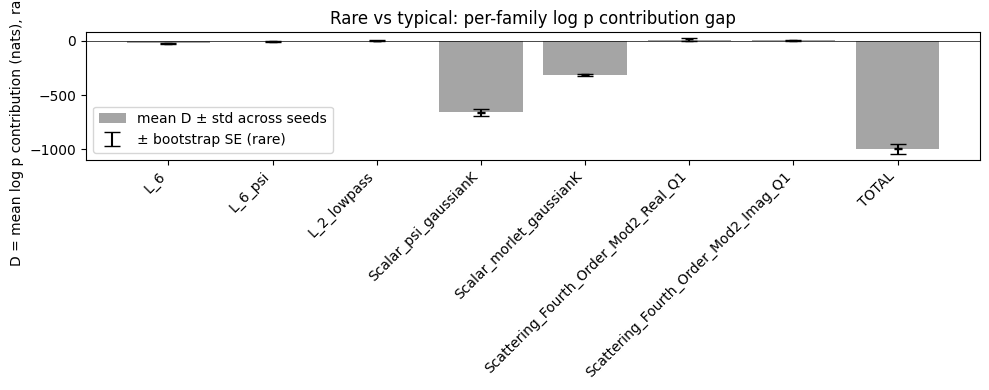

In [14]:
reg_all_np = reg_all.numpy()  # (n_seeds, n_features)
family_names_all = list(ranges_with_total.keys())  # all families + TOTAL

# C[F]: (n_seeds, n1) -- per-seed, per-signal log p contribution (nats) of family F
C = {F: reg_all_np[:, a:b] @ phi_X[:, a:b].T for F, (a, b) in ranges_with_total.items()}

D = np.stack([C[F][:, idx_rare].mean(axis=1) - C[F][:, idx_typical].mean(axis=1)
              for F in family_names_all], axis=1)  # (n_seeds, n_families+1)
D_mean = D.mean(axis=0)
D_std = D.std(axis=0, ddof=1)

# sanity check: C[TOTAL] = sum_F C[F] exactly (linear), so D[TOTAL] should equal sum_F D[F]
total_i = family_names_all.index('TOTAL')
family_sum = sum(D_mean[i] for i, F in enumerate(family_names_all) if F != 'TOTAL')
print(f"sum(family D) - TOTAL D = {family_sum - D_mean[total_i]:.3e}  (should be ~0)")

# Bootstrap SE over the rare signals only (typical held fixed), using the
# seed-averaged C -- this is exactly family_energy / total_log_p_unnorm, already computed above.
C_bar = {**family_energy, 'TOTAL': total_log_p_unnorm}
rng = np.random.default_rng(0)  # assumption: fixed seed for reproducibility, not specified
n_boot = 1000
idx_rare_arr = np.array(idx_rare)
typical_mean = {F: C_bar[F][idx_typical].mean() for F in family_names_all}
boot_D = np.empty((n_boot, len(family_names_all)))
for b in range(n_boot):
    resample = rng.choice(idx_rare_arr, size=len(idx_rare_arr), replace=True)
    boot_D[b] = [C_bar[F][resample].mean() - typical_mean[F] for F in family_names_all]
boot_se = boot_D.std(axis=0, ddof=1)
print(f"D over {n_seeds} seeds; bootstrap: {n_boot} resamples of the {len(idx_rare)} rare signals "
      f"(typical, n={len(idx_typical)}, held fixed)")

table1 = pd.DataFrame({'family': family_names_all, 'mean_D': D_mean,
                        'std_D_across_seeds': D_std, 'bootstrap_SE_rare': boot_se})
display(table1)

fig, ax = plt.subplots(figsize=(10, 4))
xpos = np.arange(len(family_names_all))
ax.bar(xpos, D_mean, yerr=D_std, capsize=3, color='tab:gray', alpha=0.7,
       label='mean D ± std across seeds')
ax.errorbar(xpos, D_mean, yerr=boot_se, fmt='none', ecolor='black', capsize=6, lw=1.5,
            label='± bootstrap SE (rare)')
ax.axhline(0, color='black', lw=0.5)
ax.set_xticks(xpos); ax.set_xticklabels(family_names_all, rotation=45, ha='right')
ax.set_ylabel('D = mean log p contribution (nats), rare - typical')
ax.set_title('Rare vs typical: per-family log p contribution gap')
ax.legend()
fig.tight_layout()
plt.show()

## 2. Robustness to the rare/typical threshold

Repeat the seed-mean `D` (no bootstrap) for each percentile in `percentiles`, split on `x1` as above. The number of rare signals at each percentile is printed below the table.

In [15]:
percentiles = [95, 99, 99.5]
table2, n_rare_p = {}, {}
for p in percentiles:
    idx_typ_p, idx_rare_p, _ = extract_rare_typical(x1, criterion='percentile', percentile=p)
    n_rare_p[f'p{p}'] = len(idx_rare_p)
    table2[f'p{p}'] = [C[F][:, idx_rare_p].mean(axis=1).mean() - C[F][:, idx_typ_p].mean(axis=1).mean()
                        for F in family_names_all]
table2_df = pd.DataFrame(table2, index=family_names_all)
display(table2_df)
print('n_rare per percentile:', n_rare_p)

,p95,p99,p99.5
L_6,-23.4,-81.8,-135
L_6_psi,-5.69,-24.7,-35.5
L_2_lowpass,0.507,1.29,3.44
Scalar_psi_gaussianK,-660,-647,-624
Scalar_morlet_gaussianK,-315,-361,-341
Scattering_Fourth_Order_Mod2_Real_Q1,7.86,154,283
Scattering_Fourth_Order_Mod2_Imag_Q1,1.48,5.32,4.67
TOTAL,-995,-954,-844


n_rare per percentile: {'p95': 250, 'p99': 50, 'p99.5': 25}


## 3. Continuous version (no split)

Extremeness `e_i` = max over time of |lag-1 increment| of `x1[i]` (same definition and units as the split). Per family: centered log p contribution vs `e_i` (log x-axis), with the `idx_rare` signals highlighted. Table: Spearman rank correlation per family.

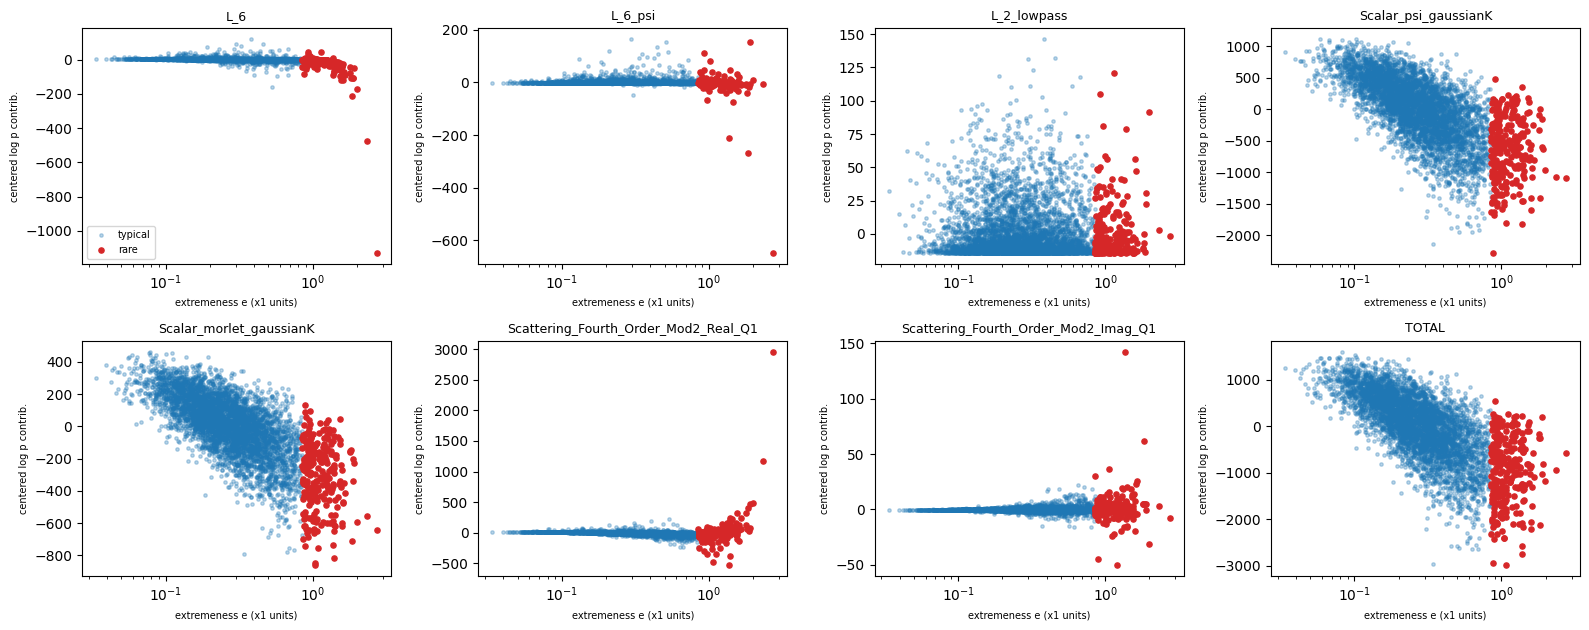

,family,spearman_rho
0,L_6,-0.461
1,L_6_psi,-0.0396
2,L_2_lowpass,-0.00631
3,Scalar_psi_gaussianK,-0.705
4,Scalar_morlet_gaussianK,-0.709
5,Scattering_Fourth_Order_Mod2_Real_Q1,-0.553
6,Scattering_Fourth_Order_Mod2_Imag_Q1,0.0575
7,TOTAL,-0.723


In [16]:
accel = compute_acceleration(x1)  # (n1, 1, M-1)
e = accel.abs().amax(dim=(1, 2)).cpu().numpy()  # (n1,) extremeness

n_cols = 4
n_rows = math.ceil(len(family_names_all) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3.2 * n_rows), squeeze=False)
mask_rare = np.zeros(n1, dtype=bool)
mask_rare[idx_rare] = True

spearman_rows = []
for i, F in enumerate(family_names_all):
    ax = axes[i // n_cols][i % n_cols]
    y = C_bar[F] - C_bar[F].mean()
    ax.scatter(e[~mask_rare], y[~mask_rare], s=6, alpha=0.3, color=category_colors['typical'], label='typical')
    ax.scatter(e[mask_rare], y[mask_rare], s=14, color=category_colors['rare'], label='rare')
    ax.set_xscale('log')
    ax.set_title(F, fontsize=9)
    ax.set_xlabel('extremeness e (x1 units)', fontsize=7)
    ax.set_ylabel('centered log p contrib.', fontsize=7)
    # Spearman = Pearson correlation of ranks (avoids a scipy import)
    rho = np.corrcoef(pd.Series(e).rank(), pd.Series(C_bar[F]).rank())[0, 1]
    spearman_rows.append({'family': F, 'spearman_rho': rho})
axes[0][0].legend(fontsize=7)
for j in range(len(family_names_all), n_rows * n_cols):
    axes[j // n_cols][j % n_cols].axis('off')
fig.tight_layout()
plt.show()

display(pd.DataFrame(spearman_rows))

## 4. Compensation between families

Correlation matrix of the families' log p contributions (seed-averaged $\theta$) across all `n1` signals. Then the sign-aware variance decomposition $\sum_{F\neq G}\mathrm{Cov}(C_F,C_G)=\mathrm{Var}(\mathrm{TOTAL})-\sum_F\mathrm{Var}(C_F)$: positive means the cross-family covariances **add** variance, negative means they **remove** it (compensation). The largest pairwise terms $2\,\mathrm{Cov}(C_F,C_G)$ are listed with their sign.

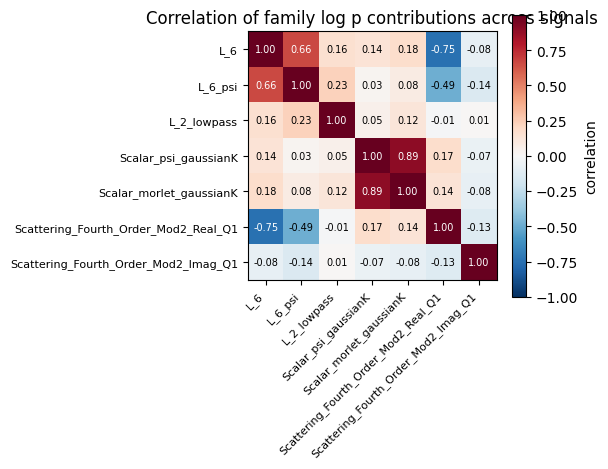

Var(TOTAL) = 5.041e+05
sum_F Var(C_F) = 3.069e+05
sum_(F!=G) Cov(C_F, C_G) = Var(TOTAL) - sum_F Var(C_F) = 1.971e+05  ->  cross-family covariance adds 64.2% of sum_F Var(C_F)
3 largest pairwise terms 2*Cov(C_F, C_G) by |value| (+ reinforces, - compensates):
  +1.791e+05   Scalar_psi_gaussianK & Scalar_morlet_gaussianK
  +1e+04   Scalar_psi_gaussianK & Scattering_Fourth_Order_Mod2_Real_Q1
  +3025   Scalar_morlet_gaussianK & Scattering_Fourth_Order_Mod2_Real_Q1


In [17]:
fam_only = list(family_ranges.keys())
C_mat = np.stack([C_bar[F] for F in fam_only], axis=0)  # (7, n1)
corr = np.corrcoef(C_mat)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(fam_only))); ax.set_xticklabels(fam_only, rotation=45, ha='right', fontsize=8)
ax.set_yticks(range(len(fam_only))); ax.set_yticklabels(fam_only, fontsize=8)
for i in range(len(fam_only)):
    for j in range(len(fam_only)):
        ax.text(j, i, f'{corr[i, j]:.2f}', ha='center', va='center', fontsize=7,
                color='white' if abs(corr[i, j]) > 0.5 else 'black')
fig.colorbar(im, ax=ax, label='correlation')
ax.set_title('Correlation of family log p contributions across signals')
fig.tight_layout()
plt.show()

var_total = C_bar['TOTAL'].var(ddof=1)
var_sum_families = sum(C_bar[F].var(ddof=1) for F in fam_only)
cross_cov = var_total - var_sum_families   # = sum_{F != G} Cov(C_F, C_G)
print(f"Var(TOTAL) = {var_total:.4g}")
print(f"sum_F Var(C_F) = {var_sum_families:.4g}")
print(f"sum_(F!=G) Cov(C_F, C_G) = Var(TOTAL) - sum_F Var(C_F) = {cross_cov:.4g}  ->  cross-family covariance "
      f"{'adds' if cross_cov > 0 else 'removes'} {100 * abs(cross_cov) / var_sum_families:.1f}% of sum_F Var(C_F)")

cov_fam = np.cov(C_mat, ddof=1)
pair_terms = [(2 * cov_fam[i, j], fam_only[i], fam_only[j])
              for i in range(len(fam_only)) for j in range(i + 1, len(fam_only))]
print("3 largest pairwise terms 2*Cov(C_F, C_G) by |value| (+ reinforces, - compensates):")
for term, F, G in sorted(pair_terms, key=lambda t: -abs(t[0]))[:3]:
    print(f"  {term:+.4g}   {F} & {G}")

## 5. Residual variance: which families are irreplaceable?

With $p_\theta\propto e^{+\theta^\top\varphi}$, write $C_F(x)=\theta_F^\top\varphi_F(x)$, so $\log p_\theta=\sum_F C_F-\log Z(\theta)$. The raw variance $\mathrm{Var}[C_F]$ overstates a family's role when other families can reproduce part of $C_F$ (compensation, near-collinear features). We therefore measure the part they cannot reproduce:
$$R_F=\min_\beta\,\mathrm{Var}\big[C_F-\beta^\top\varphi_{\bar F}\big].$$

**Why this quantity.** For an exponential family, $\mathrm{KL}(p_\theta\|p_{\theta+\delta})=\tfrac12\,\delta^\top\Sigma\,\delta+O(|\delta|^3)$ with $\Sigma=\mathrm{Cov}_{p_\theta}[\varphi]$ (standard). Removing $F$ ($\delta_F=-\theta_F$) and optimally refitting the other couplings costs, to second order, $\tfrac12 R_F$ (a Schur complement of $\Sigma$). So $R_F$ measures the information lost by dropping $F$. Computed on the rare subset, it is the same statement for $p_\theta(x\mid x\in\text{rare})$.

We report three levels, $\mathrm{Var}[C_F]\ \ge\ R_F^{\rm fam}\ \ge\ R_F$, where $R_F^{\rm fam}$ only lets other families rescale ($\beta$ acting on the $C_G$, $G\neq F$), and $R_F$ allows a full refit on the other families' features (ridge, cross-fitted). For a pair, $\mathrm{Var}[C_F+C_G]$ upper-bounds the cost of removing both: if small, $F$ and $G$ are **redundant** (each can replace the other), not individually irrelevant.

**Caveats.** (i) Variances are computed on data, a proxy for the model covariance. (ii) The expansion is local: it underestimates the cost of confining terms whose removal breaks normalizability; for such terms (plausibly L_6) small variance does not mean irrelevance. (iii) Small $R_F$ means *replaceable*, not *physically meaningless*.

*Implementation.* Both $R_F^{\rm fam}$ (least squares) and $R_F$ (ridge) are 2-fold cross-fitted on the same random split of each set: fit on one half, take residuals on the other, swap, pool. Ridge regressors are standardized on the training fold, with penalty $n_{\rm train}\,\lambda\,|\beta|^2$ and one $\lambda$ chosen on `all` (printed below).

In [18]:
sets = {'all': np.arange(n1), 'typical': np.array(idx_typical), 'rare': np.array(idx_rare)}
rng = np.random.default_rng(0)   # assumption: random 2-fold split, fixed seed
folds = {name: np.array_split(rng.permutation(idx), 2) for name, idx in sets.items()}
C64 = {F: C[F].astype(np.float64) for F in fam_only}          # (n_seeds, n1), from section 1
X_notF = {F: np.delete(phi_X, np.r_[a:b], axis=1).astype(np.float64)
          for F, (a, b) in family_ranges.items()}              # (n1, n_features - dim F)

def crossfit_resid_var(X, Y, fold_pair, lam):
    '''2-fold cross-fitted residual variance of Y (n1, k) regressed on X (n1, p) with intercept,
    columns of X standardized on the training fold; lam=None -> least squares, else ridge with
    penalty n_train * lam * |beta|^2. fold_pair holds row indices into X/Y. Returns (k,).'''
    resid = []
    for tr, te in (fold_pair, fold_pair[::-1]):
        mu, sd = X[tr].mean(0), X[tr].std(0)
        sd[sd == 0] = 1.0
        Xtr, Xte = (X[tr] - mu) / sd, (X[te] - mu) / sd
        ybar = Y[tr].mean(0)
        pen = 0.0 if lam is None else len(tr) * lam
        beta = np.linalg.solve(Xtr.T @ Xtr + pen * np.eye(X.shape[1]), Xtr.T @ (Y[tr] - ybar))
        resid.append(Y[te] - ybar - Xte @ beta)
    return np.concatenate(resid).var(axis=0, ddof=1)

def var_raw(F, set_name):
    return C64[F][:, sets[set_name]].var(axis=1, ddof=1)       # (n_seeds,)

# Ridge lambda: one value for all families, minimizing mean_{F, seeds} R_feat/var_raw on 'all'.
lam_grid = np.logspace(-6, 0, 7)
lam_score = [np.mean([(crossfit_resid_var(X_notF[F], C64[F].T, folds['all'], lam) / var_raw(F, 'all')).mean()
                      for F in fam_only]) for lam in lam_grid]
lam_ridge = lam_grid[int(np.argmin(lam_score))]
print("mean R_feat/var_raw on 'all' per lambda: "
      + ", ".join(f"{lam:.0e}: {s:.4g}" for lam, s in zip(lam_grid, lam_score)))
print(f"ASSUMPTION: ridge lambda fixed at {lam_ridge:.0e} for every set/family"
      + ("  (WARNING: at the edge of the grid)" if lam_ridge in (lam_grid[0], lam_grid[-1]) else ""))

res = {}   # (set, F) -> per-seed arrays
for set_name in sets:
    for F in fam_only:
        others = [G for G in fam_only if G != F]
        r_fam = np.array([crossfit_resid_var(np.stack([C64[G][s] for G in others], axis=1),
                                             C64[F][s][:, None], folds[set_name], None)[0]
                          for s in range(n_seeds)])
        r_feat = crossfit_resid_var(X_notF[F], C64[F].T, folds[set_name], lam_ridge)
        v = var_raw(F, set_name)
        res[set_name, F] = {'var_raw': v, 'R_fam': r_fam, 'R_feat': r_feat, 'R_feat/var_raw': r_feat / v}

# Bootstrap over rare signals, seed-averaged theta (C_bar), for R_feat/var_raw. Resampled within
# each fold, so a duplicated signal never sits in both the fitting and the evaluation half.
rng = np.random.default_rng(0)
n_boot = 1000
f0, f1 = folds['rare']
boot_ratio = np.empty((n_boot, len(fam_only)))
for bi in range(n_boot):
    bfolds = (rng.choice(f0, len(f0)), rng.choice(f1, len(f1)))
    bidx = np.concatenate(bfolds)
    for j, F in enumerate(fam_only):
        y = C_bar[F].astype(np.float64)[:, None]
        boot_ratio[bi, j] = crossfit_resid_var(X_notF[F], y, bfolds, lam_ridge)[0] / y[bidx].var(ddof=1)
rare_point = [crossfit_resid_var(X_notF[F], C_bar[F].astype(np.float64)[:, None], folds['rare'], lam_ridge)[0]
              / C_bar[F][idx_rare].var(ddof=1) for F in fam_only]

quantities = ['var_raw', 'R_fam', 'R_feat', 'R_feat/var_raw']
table_rv = pd.DataFrame({(set_name, q): [f"{res[set_name, F][q].mean():.3g} ± {res[set_name, F][q].std(ddof=1):.2g}"
                                         for F in fam_only]
                         for set_name in sets for q in quantities}, index=fam_only)
table_rv[('rare', 'R_feat/var_raw, mean theta ± boot SE')] = [
    f"{p:.3g} ± {se:.2g}" for p, se in zip(rare_point, boot_ratio.std(axis=0, ddof=1))]
print(f"mean ± std across {n_seeds} seeds; set sizes: " + ", ".join(f"{k} = {len(v)}" for k, v in sets.items())
      + f"; bootstrap: {n_boot} resamples of the rare signals")
display(table_rv)

n_viol = sum(int((r['R_fam'] > r['var_raw']).sum() + (r['R_feat'] > r['R_fam']).sum()) for r in res.values())
print(f"(set, family, seed) cases breaking var_raw >= R_fam >= R_feat (estimation noise): "
      f"{n_viol} of {2 * len(res) * n_seeds} comparisons")

mean R_feat/var_raw on 'all' per lambda: 1e-06: 6.696, 1e-05: 7.169, 1e-04: 5.699, 1e-03: 2.657, 1e-02: 1.025, 1e-01: 0.5842, 1e+00: 0.5504
ASSUMPTION: ridge lambda fixed at 1e+00 for every set/family  (WARNING: at the edge of the grid)
mean ± std across 50 seeds; set sizes: all = 5000, typical = 4750, rare = 250; bootstrap: 1000 resamples of the rare signals


all                      \
                                                 var_raw               R_fam   
L_6                                        437 ± 1.2e+02       288 ± 1.3e+02   
L_6_psi                                         237 ± 76            197 ± 96   
L_2_lowpass                                     409 ± 47            480 ± 98   
Scalar_psi_gaussianK                  2.65e+05 ± 1.8e+03  5.33e+04 ± 1.1e+03   
Scalar_morlet_gaussianK               3.81e+04 ± 5.2e+02  7.57e+03 ± 1.5e+02   
Scattering_Fourth_Order_Mod2_Real_Q1  3.17e+03 ± 4.3e+02   2.2e+03 ± 4.7e+02   
Scattering_Fourth_Order_Mod2_Imag_Q1           43.6 ± 22           48.5 ± 23   

                                                                          \
                                                  R_feat  R_feat/var_raw   
L_6                                             137 ± 45    0.31 ± 0.039   
L_6_psi                                        99.4 ± 32      0.43 ± 0.1   
L_2_lowpass                                   49.3 ± 5.6  0.12 ± 6.1e-10   
Scalar_psi_gaussianK                  5.51e+04 ± 1.6e+02  0.208 ± 0.0014   
Scalar_morlet_gaussianK                    4.27e+03 ± 36  0.112 ± 0.0015   
Scattering_Fourth_Order_Mod2_Real_Q1  4.12e+03 ± 5.7e+02      1.3 ± 0.13   
Scattering_Fourth_Order_Mod2_Imag_Q1           58.3 ± 31     1.37 ± 0.35   

                                                 typical                      \
                                                 var_raw               R_fam   
L_6                                            70.1 ± 19           49.9 ± 18   
L_6_psi                                        97.3 ± 44           81.9 ± 45   
L_2_lowpass                                     407 ± 47            306 ± 48   
Scalar_psi_gaussianK                  2.44e+05 ± 1.6e+03  4.95e+04 ± 6.3e+02   
Scalar_morlet_gaussianK                3.3e+04 ± 4.1e+02  6.84e+03 ± 1.1e+02   
Scattering_Fourth_Order_Mod2_Real_Q1            516 ± 96            379 ± 72   
Scattering_Fourth_Order_Mod2_Imag_Q1          10.8 ± 4.4          10.7 ± 4.4   

                                                                           \
                                                  R_feat   R_feat/var_raw   
L_6                                           9.43 ± 3.2    0.134 ± 0.026   
L_6_psi                                       21.4 ± 9.5    0.235 ± 0.084   
L_2_lowpass                                   49.9 ± 5.7  0.123 ± 7.9e-10   
Scalar_psi_gaussianK                  5.23e+04 ± 1.5e+02   0.215 ± 0.0013   
Scalar_morlet_gaussianK                    4.05e+03 ± 36   0.123 ± 0.0015   
Scattering_Fourth_Order_Mod2_Real_Q1            269 ± 40    0.527 ± 0.055   
Scattering_Fourth_Order_Mod2_Imag_Q1          11.2 ± 4.6      1.04 ± 0.07   

                                                    rare                      \
                                                 var_raw               R_fam   
L_6                                    6.9e+03 ± 2.2e+03  1.97e+03 ± 1.2e+03   
L_6_psi                               2.85e+03 ± 1.1e+03  3.75e+03 ± 1.7e+03   
L_2_lowpass                                     452 ± 52            529 ± 82   
Scalar_psi_gaussianK                  2.54e+05 ± 1.8e+03  9.14e+04 ± 1.4e+04   
Scalar_morlet_gaussianK               4.21e+04 ± 6.3e+02    1.54e+04 ± 2e+03   
Scattering_Fourth_Order_Mod2_Real_Q1    5.36e+04 ± 8e+03   2.6e+04 ± 9.1e+03   
Scattering_Fourth_Order_Mod2_Imag_Q1       666 ± 4.2e+02       785 ± 3.7e+02   

                                                                           \
                                                  R_feat   R_feat/var_raw   
L_6                                   1.14e+03 ± 4.4e+02    0.162 ± 0.024   
L_6_psi                                 1.93e+03 ± 8e+02     0.705 ± 0.23   
L_2_lowpass                                    93.3 ± 11  0.207 ± 4.4e-09   
Scalar_psi_gaussianK                  9.93e+04 ± 5.1e+02    0.39 ± 0.0025   
Scalar_morlet_gaussianK                    1.08e+

(set, family, seed) cases breaking var_raw >= R_fam >= R_feat (estimation noise): 580 of 2100 comparisons


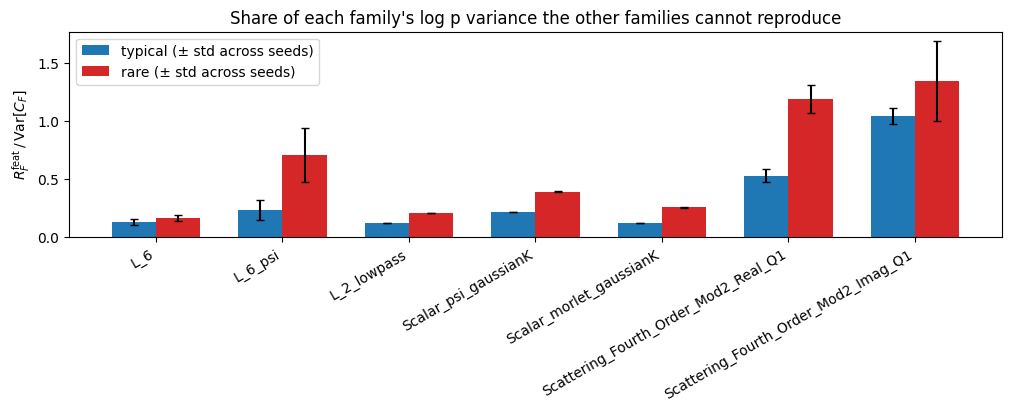

typical: lowest R_feat/var_raw (most replaceable) = L_2_lowpass (0.123); highest (least replaceable) = Scattering_Fourth_Order_Mod2_Imag_Q1 (1.04)
rare: lowest R_feat/var_raw (most replaceable) = L_6 (0.162); highest (least replaceable) = Scattering_Fourth_Order_Mod2_Imag_Q1 (1.34)

Rare set: Var[C_F + C_G] / (Var[C_F] + Var[C_G])


,L_6,L_6_psi,L_2_lowpass,Scalar_psi_gaussianK,Scalar_morlet_gaussianK,Scattering_Fourth_Order_Mod2_Real_Q1,Scattering_Fourth_Order_Mod2_Imag_Q1
L_6,NaN,1.7,1,1.04,1.13,0.446,0.985
L_6_psi,1.7,NaN,1.08,1.02,1.09,0.725,0.878
L_2_lowpass,1,1.08,NaN,0.997,0.993,1,0.95
Scalar_psi_gaussianK,1.04,1.02,0.997,NaN,1.59,1.03,0.998
Scalar_morlet_gaussianK,1.13,1.09,0.993,1.59,NaN,0.936,0.989
Scattering_Fourth_Order_Mod2_Real_Q1,0.446,0.725,1,1.03,0.936,NaN,0.986
Scattering_Fourth_Order_Mod2_Imag_Q1,0.985,0.878,0.95,0.998,0.989,0.986,NaN


L_6 + Scattering_Fourth_Order_Mod2_Real_Q1: 0.446


In [19]:
fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
xpos = np.arange(len(fam_only))
for i, set_name in enumerate(['typical', 'rare']):
    ratio = np.stack([res[set_name, F]['R_feat/var_raw'] for F in fam_only])   # (n_families, n_seeds)
    ax.bar(xpos + (i - 0.5) * 0.35, ratio.mean(1), 0.35, yerr=ratio.std(1, ddof=1), capsize=3,
           color=category_colors[set_name], label=f'{set_name} (± std across seeds)')
ax.set_xticks(xpos); ax.set_xticklabels(fam_only, rotation=30, ha='right')
ax.set_ylabel(r'$R_F^{\rm feat}\,/\,\mathrm{Var}[C_F]$')
ax.set_title('Share of each family\'s log p variance the other families cannot reproduce')
ax.legend()
plt.show()

for set_name in ['typical', 'rare']:
    r = {F: res[set_name, F]['R_feat/var_raw'].mean() for F in fam_only}
    order = sorted(r, key=r.get)
    print(f"{set_name}: lowest R_feat/var_raw (most replaceable) = {order[0]} ({r[order[0]]:.3g}); "
          f"highest (least replaceable) = {order[-1]} ({r[order[-1]]:.3g})")

# Pair check on the rare set, seed-averaged theta: Var[C_F + C_G] / (Var[C_F] + Var[C_G])
# (= 1 if uncorrelated, << 1 means F and G compensate each other; diagonal left blank).
C_rare = np.stack([C_bar[F][idx_rare] for F in fam_only]).astype(np.float64)
v_rare = C_rare.var(axis=1, ddof=1)
pair_ratio = pd.DataFrame([[np.nan if i == j else (C_rare[i] + C_rare[j]).var(ddof=1) / (v_rare[i] + v_rare[j])
                            for j in range(len(fam_only))] for i in range(len(fam_only))],
                          index=fam_only, columns=fam_only)
print("\nRare set: Var[C_F + C_G] / (Var[C_F] + Var[C_G])")
display(pair_ratio)
print(f"L_6 + {REAL_KEY}: {pair_ratio.loc['L_6', REAL_KEY]:.4g}")

**Reading (TODO: fill in after running, from the printed lines above; no hardcoded numbers).**

## 6. Model samples

First check which seeds have a final-sample file under `saved_results/samples/`. If none are found, stop here: the rest of this section assumes at least one exists.

In [20]:
sample_path = {}   # seed_key -> path of that seed's samples file
for key in seed_keys:
    p = root / "saved_results" / "samples" / config_by_seed[key]
    p_pt = p.with_name(p.name + ".pt")
    path = p_pt if p_pt.exists() else (p if p.exists() else None)
    if path is not None:
        sample_path[key] = path
n_found = len(sample_path)
print(f"{n_found}/{len(seed_keys)} seeds have a samples file")

50/50 seeds have a samples file


Load each seed's final-time sample, compute phi with that seed's own fitted potentials, and check whether samples need `normalize()` to match `x1`'s convention (checked once, assumed the same for every seed). GPU memory: samples move to `device` only for the `compute_phi_X` call, then are freed immediately.

In [21]:
# Reuses potentials_by_seed[key] -- each seed's OWN fitted potentials, already cached
# during the seed-loading loop above -- so each seed's theta pairs with phi(x) from
# that SAME seed's fitted potentials (as fit), not the shared potentials_ref.
model_norm_checked = False
needs_norm = None
C_model = {}   # seed_key -> {family: (n_model,) array}, includes 'TOTAL'
e_model = {}   # seed_key -> (n_model,) extremeness, same lag-1/max|.| definition and units as the split on x1

for key, path in sample_path.items():
    x_t = torch.load(path, map_location='cpu')
    x_final = x_t 

    if not model_norm_checked:
        m, s = x_final.mean().item(), x_final.std().item()
        needs_norm = not (abs(m) < 0.05 and abs(s - 1) < 0.05)
        print(f"model samples: mean={m:.4g} std={s:.4g} -> "
              f"{'applying' if needs_norm else 'skipping'} normalize() (checked on {key} only)")
        model_norm_checked = True

    x_model = normalize(x_final) if needs_norm else x_final   # CPU; same tensor for phi and extremeness
    phi_model = compute_phi_X(potentials_by_seed[key], x_model.to(device)).detach().cpu().numpy()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    s_idx = seed_keys.index(key)
    c_this = {F: phi_model[:, a:b] @ reg_all_np[s_idx, a:b] for F, (a, b) in family_ranges.items()}
    c_this['TOTAL'] = sum(c_this.values())
    C_model[key] = c_this

    accel_model = compute_acceleration(x_model)
    e_model[key] = accel_model.abs().amax(dim=tuple(range(1, accel_model.ndim))).numpy()

print(f"Computed model-sample phi/log-p contributions for {len(C_model)} seeds.")

model samples: mean=0.02269 std=0.9994 -> skipping normalize() (checked on seed300 only)
Computed model-sample phi/log-p contributions for 50 seeds.


### 6a. Data vs model: TOTAL log p contribution and per-family std

Same-seed theta on data (from section 1's `C`) vs on that seed's model samples, pooled across seeds.

L_6                                           data std=     20.92   model std=     17.18
L_6_psi                                       data std=     15.41   model std=     14.14
L_2_lowpass                                   data std=     20.25   model std=     20.25
Scalar_psi_gaussianK                          data std=     514.5   model std=     161.8
Scalar_morlet_gaussianK                       data std=     195.3   model std=     101.3
Scattering_Fourth_Order_Mod2_Real_Q1          data std=     56.33   model std=     50.25
Scattering_Fourth_Order_Mod2_Imag_Q1          data std=     6.607   model std=     8.865


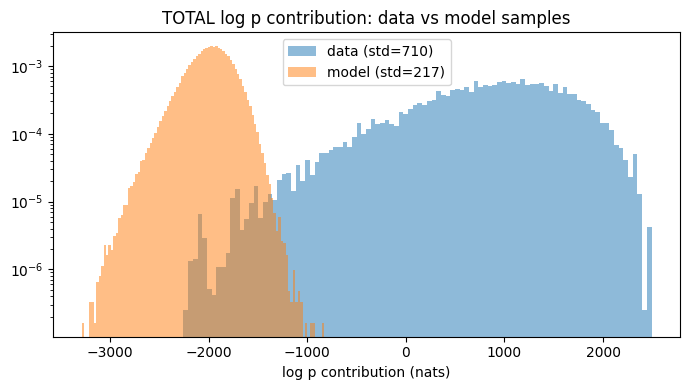

TOTAL mean: data = 869.3, model = -1989 (each seed's own theta, pooled over 50 seeds)


In [22]:
model_keys = list(C_model.keys())
for F in family_names_all:
    data_vals = np.concatenate([C[F][seed_keys.index(k)] for k in model_keys])
    model_vals = np.concatenate([C_model[k][F] for k in model_keys])
    if F == 'TOTAL':
        fig, ax = plt.subplots(figsize=(7, 4))
        ax.hist(data_vals, bins=100, density=True, alpha=0.5, color='tab:blue',
                label=f'data (std={data_vals.std():.3g})')
        ax.hist(model_vals, bins=100, density=True, alpha=0.5, color='tab:orange',
                label=f'model (std={model_vals.std():.3g})')
        ax.set_yscale('log'); ax.legend()
        ax.set_xlabel('log p contribution (nats)')
        ax.set_title('TOTAL log p contribution: data vs model samples')
        fig.tight_layout(); plt.show()
        print(f"TOTAL mean: data = {data_vals.mean():.4g}, model = {model_vals.mean():.4g} "
              f"(each seed's own theta, pooled over {len(model_keys)} seeds)")
    else:
        print(f"{F:45s} data std={data_vals.std():10.4g}   model std={model_vals.std():10.4g}")

**Caveat (not resolved here).** The model samples sit far below the data in $\theta_{\rm reg}^\top\varphi$ (TOTAL means printed above). The MGD samples are not guaranteed to be samples of $p_{\Theta_{\rm reg}}$: $\Theta_{\rm reg}$ is a separate regularised fit, not the $\theta$ that drove the sampler.

### 6b. Rare fraction: model vs data, same cutoff

Apply the data cutoff `cutoff_p95` (from the split on `x1`) to the model samples' max |lag-1 increment|, computed in the same normalized units.

In [23]:
model_rare_frac = np.array([(e_model[k] > cutoff_p95).mean() for k in C_model])
data_rare_frac = len(idx_rare) / n1

print(f"data rare fraction (p{info_split['percentile']} of x1, by construction) = {data_rare_frac:.4f}")
print(f"model rare fraction (same cutoff_p95 = {cutoff_p95:.4g}, x1 units): "
      f"mean={model_rare_frac.mean():.4f}, std={model_rare_frac.std(ddof=1):.4f} across {len(C_model)} seeds")
print("CAVEAT: cutoff and both extremeness values are in x1's normalized units. Model samples are taken to "
      "already be in those units (mean/std checked on one seed only, in the loading cell above).")

n_model_rare_total = int(sum((e_model[k] > cutoff_p95).sum() for k in C_model))
if n_model_rare_total < 20:
    _, _, info99 = extract_rare_typical(x1, criterion='percentile', percentile=99)
    cutoff_p99 = info99['cutoff']
    model_rare_frac_99 = np.array([(e_model[k] > cutoff_p99).mean() for k in C_model])
    print(f"\nOnly {n_model_rare_total} model-rare samples total (<20) -> also using the data "
          f"p{info99['percentile']} cutoff ({cutoff_p99:.4g}): mean model rare fraction = "
          f"{model_rare_frac_99.mean():.4f}")

data rare fraction (p95 of x1, by construction) = 0.0500
model rare fraction (same cutoff_p95 = 0.8473, x1 units): mean=0.0218, std=0.0013 across 50 seeds
CAVEAT: cutoff and both extremeness values are in x1's normalized units. Model samples are taken to already be in those units (mean/std checked on one seed only, in the loading cell above).
